# 05 · The rescan game: a policy that holds up when shoppers adapt

The risk model says who looks risky. The policy decides **who gets a full rescan, with what
probability**, using the same colleague time as today. It has to work against shoppers who learn
it: a policy that only works while thieves are unaware of it does not work.

**The game (Stackelberg).** The store leads: it commits to a policy, a function from risk score
to the probability of a full rescan, which shoppers learn over time. Shoppers follow:
- **opportunists** steal on impulse, less often the likelier a rescan
- **adaptive shoppers** choose how much to take (0, 25, 50 or 100% of their usual haul) to
  maximise *haul × (1 − q·d) − q·d·penalty*. Taking less keeps the scan log calmer and the risk
  score lower: the way to slip under a threshold
- **everyone else** is unaffected (honest and careless shoppers do not steal; deliberate ones are
  not deterred)

For every session, each version of reality (honest, and each haul size) is simulated once from
the same random draws, with its own scan log, risk score, loss and rescan findings. Evaluating a
policy is then exact: work out each shopper's best choice under it and add up.

**Rules.** Every policy uses today's colleague time. Policy *shapes* are fitted on the tuning
period (days 331–500); the test period (501–711) only evaluates, with rescan *volume* set to its
budget, as a store sets volume to its staffing each week. Every policy keeps a **2% random floor**
of full rescans: the unbiased measurement and training labels from weeks 3 and 5.

**Simplification.** Member history is held at today's; the game is played one session at a time.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from smartshop.basket.data import prepare
from smartshop.policy.game import outcome, responses, threshold_policy, fit_to_budget, today_hours
from smartshop.policy.search import FAMILIES, compare, make_policy, recalibrate, solve
from smartshop.risk.model import MODEL_PATH, load_features
from smartshop.viz import BLUE, GREY, ORANGE, TEXT_2, money, pct, save, set_style, subtitle
from smartshop.warehouse import connect

set_style()
con = connect()
prepare(con)
base = load_features(con)
bundle = joblib.load(MODEL_PATH)
g_tune, g_test, fitted = solve(con, base, bundle['model'], bundle['features'])
budget = today_hours(g_test)
print(f'{len(g_tune):,} tuning sessions, {len(g_test):,} test sessions; budget {budget:.1f} colleague hours')

30,386 tuning sessions, 47,314 test sessions; budget 113.4 colleague hours


## 1. The engine reproduces today

In [2]:
today = outcome(g_test, None, today=True)
pd.Series({k: today[k] for k in ['recovered', 'colleague_hours', 'recovered_per_hour',
                                  'honest_stop_rate', 'opportunists_stealing', 'adaptive_stealing']}).round(3)

recovered                1195.783
colleague_hours           113.444
recovered_per_hour         10.541
honest_stop_rate            0.120
opportunists_stealing       0.178
adaptive_stealing           0.663
dtype: float64

Today's random rescans recover about \$10 per colleague hour, and 18% of opportunist and 67% of
adaptive sessions involve stealing: the same as the simulator in week 3.

## 2. What stealing does to a shopper's risk score

In [3]:
s = g_test.sessions
rows = []
for typ in ['opportunist', 'adaptive']:
    d = s[s.gt_type == typ]
    for k, lv in enumerate((0,) + g_test.levels):
        rows.append({'type': typ, 'haul taken': lv, 'avg haul $': d[f'v{k}_deliberate_value'].mean(),
                     'avg risk score': d[f'v{k}_score'].mean()})
pd.DataFrame(rows).pivot(index='haul taken', columns='type').round(3)

avg haul $             avg risk score            
type         adaptive opportunist       adaptive opportunist
haul taken                                                  
0.00            0.000       0.000          0.219       0.196
0.25            2.665       1.930          0.250       0.214
0.50            5.329       3.852          0.268       0.228
1.00           10.452       7.669          0.299       0.250

Stealing raises the score, but only a little: the risk model's signals are weak (week 5), so a
thief who takes less looks nearly as calm as an honest shopper.

## 3. Policies, same colleague time (test period)

In [4]:
table = compare(g_test, fitted, hours=budget)
cols = ['loss_remaining', 'recovered', 'recovered_per_hour', 'honest_stops', 'colleague_hours',
        'opportunists_stealing', 'adaptive_stealing', 'adaptive_holding_back']
table[cols].round(3)

,loss_remaining,recovered,recovered_per_hour,honest_stops,colleague_hours,opportunists_stealing,adaptive_stealing,adaptive_holding_back
policy,,,,,,,,
Today: random partial + full,41639.170,1195.783,10.541,5428.200,113.444,0.178,0.663,0.115
Random full rescans,40851.001,3022.790,26.646,3181.537,113.444,0.218,0.732,0.145
Threshold + random floor,35604.640,7301.777,64.399,1578.720,113.383,0.259,0.771,0.213
"Randomised, no cap",35520.327,7483.771,65.969,1604.910,113.444,0.252,0.767,0.204
"Randomised, cap 0.5 (recommended)",36766.742,6482.822,57.146,1664.886,113.444,0.249,0.775,0.199
"Randomised, cap 0.3",37841.402,5578.241,49.172,1765.234,113.444,0.242,0.776,0.193


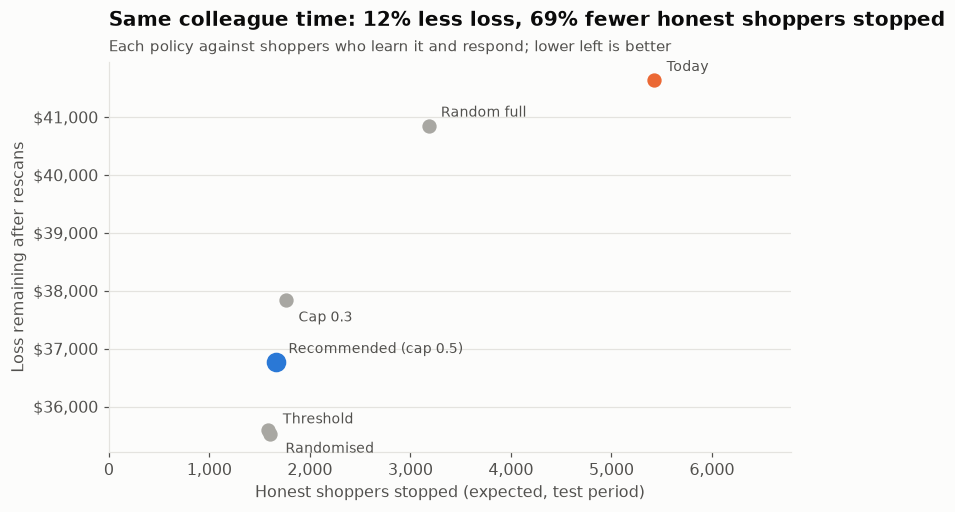

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.6))
short = {'Today: random partial + full': 'Today', 'Random full rescans': 'Random full',
         'Threshold + random floor': 'Threshold', 'Randomised, no cap': 'Randomised',
         'Randomised, cap 0.5 (recommended)': 'Recommended (cap 0.5)', 'Randomised, cap 0.3': 'Cap 0.3'}
for name, r in table.iterrows():
    rec = 'recommended' in name
    ax.scatter(r.honest_stops, r.loss_remaining, s=140 if rec else 70,
               color=BLUE if rec else (ORANGE if name.startswith('Today') else GREY), zorder=3)
    offset = {'Randomised, no cap': (10, -12), 'Randomised, cap 0.3': (8, -14),
              'Threshold + random floor': (10, 4)}.get(name, (8, 6))
    ax.annotate(short[name], (r.honest_stops, r.loss_remaining), textcoords='offset points',
                xytext=offset, color=TEXT_2, fontsize=9)
ax.yaxis.set_major_formatter(money())
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _p: f'{x:,.0f}'))
ax.set_xlabel('Honest shoppers stopped (expected, test period)')
ax.set_ylabel('Loss remaining after rescans')
rec = table.loc['Randomised, cap 0.5 (recommended)']
ax.set_title(f"Same colleague time: {1 - rec.loss_remaining / today['loss_remaining']:.0%} less loss, "
             f"{1 - rec.honest_stops / today['honest_stops']:.0%} fewer honest shoppers stopped")
subtitle(ax, 'Each policy against shoppers who learn it and respond; lower left is better')
ax.set_xlim(0, table.honest_stops.max() * 1.25)
save(fig, '13_policy_frontier')
fig

## 4. Why evaluate against shoppers who respond

The same threshold policy, judged two ways: against shoppers who keep behaving as they do today
(what a static evaluation assumes), and against shoppers who learn the policy.

In [6]:
thr = make_policy(recalibrate(g_test, fitted['Threshold + random floor'], budget))
cols_idx = np.arange(len(s))
pick = lambda v, ch: g_test.matrix(v)[ch, cols_idx]
ch_static = responses(g_test, None, q_today=0.12)
static_recovered = (thr(pick('score', ch_static)) * pick('full_find', ch_static)).sum()
static_remaining = pick('net_loss', ch_static).sum() - static_recovered
real = outcome(g_test, thr)
naive = pd.DataFrame({'static shoppers (naive)': [static_recovered, static_remaining],
                      'shoppers who respond': [real['recovered'], real['loss_remaining']]},
                     index=['recovered', 'loss remaining']).round(0)
naive['overstatement'] = (naive.iloc[:, 0] / naive.iloc[:, 1] - 1).round(3)
naive

,static shoppers (naive),shoppers who respond,overstatement
recovered,9990.0,7302.0,0.368
loss remaining,32845.0,35605.0,-0.078


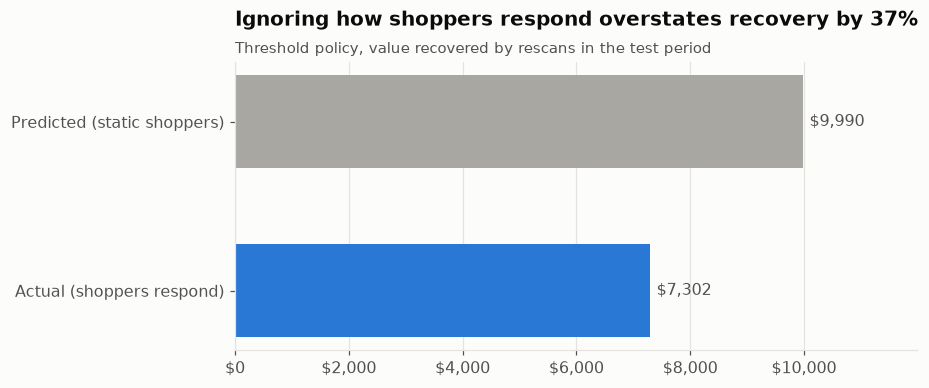

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.4))
vals = [static_recovered, real['recovered']]
bars = ax.barh(['Predicted (static shoppers)', 'Actual (shoppers respond)'], vals, color=[GREY, BLUE], height=0.55)
ax.bar_label(bars, labels=[f'${v:,.0f}' for v in vals], padding=4, color=TEXT_2)
ax.xaxis.set_major_formatter(money())
ax.invert_yaxis()
ax.grid(axis='x'); ax.grid(axis='y', visible=False)
ax.set_xlim(0, max(vals) * 1.2)
ax.set_title(f'Ignoring how shoppers respond overstates recovery by {static_recovered / real["recovered"] - 1:.0%}')
subtitle(ax, 'Threshold policy, value recovered by rescans in the test period')
save(fig, '14_static_vs_strategic')
fig

## 5. Does randomising beat a threshold?

Game theory says a deterministic threshold can be exploited, and it is: under the threshold
about a fifth of adaptive sessions hold back to stay under it. But randomising recovers little
of that here. To deter an adaptive shopper, the rescan chance they face must exceed
*haul / (d·(penalty + haul))*; the table shows how high that is for the hauls they actually
plan, against the chance a policy can afford to give them.

In [8]:
cfg = g_test.cfg
d, pen = cfg.adaptive_perceived_detection, cfg.adaptive_penalty
ada = s[s.gt_type == 'adaptive']
haul = ada[f'v{len(g_test.levels)}_deliberate_value']
q_needed = (haul / (d * (pen + haul)))[haul > 0]
rec_policy = make_policy(recalibrate(g_test, fitted['Randomised, cap 0.5 (recommended)'], budget))
q_faced = rec_policy(ada[f'v{len(g_test.levels)}_score'].to_numpy())
pd.Series({'median rescan chance needed to deter (full haul)': q_needed.median(),
           'share of adaptive sessions deterrable at 10%': (q_needed < 0.10).mean(),
           'median rescan chance faced under recommended policy': np.median(q_faced),
           'average full-rescan rate the budget allows': table.loc['Random full rescans', 'rescans'] / len(s)}).round(3)

median rescan chance needed to deter (full haul)       0.327
share of adaptive sessions deterrable at 10%           0.134
median rescan chance faced under recommended policy    0.020
average full-rescan rate the budget allows             0.071
dtype: float64

Deterring a typical adaptive shopper would need a rescan chance of about a third, far beyond what
the budget allows (about 7% of sessions get a full rescan). So the store cannot buy deterrence
from them with randomisation; it wins by **detection**, catching thieves whose scan logs give them
away. That makes the best policy here close to a threshold with a random floor; randomising
mainly earns its place through the cap (section 6). If thieves were more cautious (a higher
perceived penalty), deterrence would matter more: week 8 tests that.

Today's many cheap partial rescans do deter: under random *full* rescans at the same cost (fewer
rescans), more opportunists steal (22% vs 18%). The recommended policy accepts a little less
deterrence for about 5x the recovery.

## 6. Fairness: who gets stopped, and how often

In [9]:
demo = con.sql('SELECT * FROM staging.stg_member_demographics').df()

def fairness(policy):
    ch = responses(g_test, policy)
    p = policy(pick('score', ch))
    honest = pick('deliberate_value', ch) == 0
    df = pd.DataFrame({'member_id': s.member_id, 'p': p, 'honest': honest})
    out = {}
    d2 = df.merge(demo, on='member_id', how='left')
    for col in ['age_group', 'household_size', 'income_level']:
        dd = d2[d2.honest].dropna(subset=[col])
        r = dd.groupby(col).agg(rate=('p', 'mean'), n=('p', 'size'))
        r = r[r.n >= 200]
        out[f'honest-stop ratio: {col}'] = r.rate.min() / r.rate.max()
    m = df.groupby('member_id').p.mean()
    out['highest member rescan rate'] = m.max()
    out['members rescanned on >50% of trips'] = int((m > 0.5).sum())
    return out

rows = {}
for name, params in fitted.items():
    pol = make_policy(recalibrate(g_test, params, budget))
    rows[name] = {'loss remaining': outcome(g_test, pol)['loss_remaining'], **fairness(pol)}
pd.DataFrame(rows).T.round(3)

,loss remaining,honest-stop ratio: age_group,honest-stop ratio: household_size,honest-stop ratio: income_level,highest member rescan rate,members rescanned on >50% of trips
Random full rescans,40851.001,1.000,1.000,1.000,0.071,0.0
Threshold + random floor,35604.640,0.533,0.688,0.425,1.000,6.0
"Randomised, no cap",35520.327,0.580,0.690,0.491,1.000,3.0
"Randomised, cap 0.5 (recommended)",36766.742,0.599,0.630,0.542,0.500,0.0
"Randomised, cap 0.3",37841.402,0.655,0.647,0.553,0.300,0.0


Random selection is fair by construction but recovers little. Every risk-based policy stops
honest shoppers far less often overall, but not equally across groups: households with bigger
baskets are stopped more (week 5). The cap's clear effect is on **individuals**: with a cap of 0.5
no member is rescanned on more than half their trips on average (without a cap, some honest
members would be rescanned on nearly every trip). Its effect on **group** gaps is small and mixed
(better for age and income, worse for household size, within the noise of groups with very few
households). **Recommended: cap 0.5**, for about 3% more loss than an uncapped threshold. The group
gaps are not solved by the policy; they are a monitored review item (week 10) and a reason the
colleague, not the score, makes the call.

## Findings

| # | Finding | Implication |
|---|---|---|
| 1 | Same colleague time as today: the recommended policy leaves 12% less loss, recovers 5.4x as much (\$11 to \$57 per colleague hour) and stops 69% fewer honest shoppers | Rescans go where they find things |
| 2 | Judged against shoppers who keep today's behaviour, the threshold policy's recovery is overstated by 37% | Policies must be evaluated against shoppers who learn them |
| 3 | Adaptive shoppers do exploit the threshold (about a fifth hold back), but randomising gains little: deterring them needs about a one-in-three rescan chance, and the budget allows about 7% on average | Here the store wins by detection, not deterrence; the policy is close to threshold + floor |
| 4 | Today's cheap partial rescans deter some opportunists; fewer, targeted full rescans deter less but find far more | A deliberate trade, quantified |
| 5 | Risk-based policies stop honest shoppers unequally across age, household size and income; a cap of 0.5 ensures no one is rescanned on more than half their trips, but moves group gaps only a little, in both directions | Cap 0.5 recommended; group gaps stay a monitored review item (week 10) |
| 6 | The 2% random floor stays in every policy | Unbiased loss measurement and training labels (weeks 3 and 5) |

**Assumptions to stress-test (week 8):** the adaptive shopper's penalty and perceived detection,
the opportunists' sensitivity to rescans, and weaker risk signals.